In [1]:
# Install necessary libraries
!pip install pandas plotly folium altair

# Import libraries
import pandas as pd
import plotly.express as px
import folium
from folium.plugins import MarkerCluster
import altair as alt


Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


In [3]:
# Load the datasets
dataset = pd.read_csv('dataset.csv')
climate_policy_df = pd.read_csv('final_df_with_climate_and_policy.csv')
migrant_incidents_df = pd.read_csv('North_America_Incidents.csv')
cbp_encounters_df = pd.read_csv('U.S.CustomsandBorderProtection(CBP)Encounters ____________ - Sheet1.csv')

# Quick preview
print("Dataset shape:", dataset.shape)
print("Climate & Policy Data shape:", climate_policy_df.shape)
print("North America Incidents shape:", migrant_incidents_df.shape)
print("CBP Encounters shape:", cbp_encounters_df.shape)




Dataset shape: (4992, 7)
Climate & Policy Data shape: (4308, 9)
North America Incidents shape: (4308, 25)
CBP Encounters shape: (55, 10)


In [4]:
print(migrant_incidents_df.columns.tolist())



['Main ID', 'Incident ID', 'Incident Type', 'Region of Incident', 'Incident Date', 'Incident Year', 'Month', 'Number of Dead', 'Minimum Estimated Number of Missing', 'Total Number of Dead and Missing', 'Number of Survivors', 'Number of Females', 'Number of Males', 'Number of Children', 'Country of Origin', 'Region of Origin', 'Cause of Death', 'Country of Incident', 'Migration Route', 'Location of Incident', 'Coordinates', 'UNSD Geographical Grouping', 'Information Source', 'URL', 'Source Quality']


In [5]:
# Try different possible column names
possible_date_cols = ['Date', 'Reported Date', 'Incident Date', 'date', 'Reported_Date']

# Find which one exists
found_date_col = None
for col in possible_date_cols:
    if col in migrant_incidents_df.columns:
        found_date_col = col
        break

if found_date_col:
    migrant_incidents_df[found_date_col] = pd.to_datetime(migrant_incidents_df[found_date_col], errors='coerce')
    migrant_incidents_df['Parsed_Date'] = migrant_incidents_df[found_date_col]
else:
    print("❌ No date column found!")

# Same thing for dropping missing locations
if 'Latitude' in migrant_incidents_df.columns and 'Longitude' in migrant_incidents_df.columns:
    migrant_incidents_df = migrant_incidents_df.dropna(subset=['Latitude', 'Longitude'])
else:
    print("❌ No Latitude/Longitude columns found!")


❌ No Latitude/Longitude columns found!


In [6]:
# Try different possible column names
possible_date_cols = ['Date', 'Reported Date', 'Incident Date', 'date', 'Reported_Date', 'ReportedDate']

# Find which one exists
found_date_col = None
for col in possible_date_cols:
    if col in migrant_incidents_df.columns:
        found_date_col = col
        break

if found_date_col:
    migrant_incidents_df[found_date_col] = pd.to_datetime(migrant_incidents_df[found_date_col], errors='coerce')
    migrant_incidents_df['Parsed_Date'] = migrant_incidents_df[found_date_col]
else:
    print("❌ No date column found!")

# Same thing for dropping missing locations
if 'Latitude' in migrant_incidents_df.columns and 'Longitude' in migrant_incidents_df.columns:
    migrant_incidents_df = migrant_incidents_df.dropna(subset=['Latitude', 'Longitude'])
else:
    print("❌ No Latitude/Longitude columns found!")

# Assuming 'ReportedDate' or a similar variation is the actual column name
migrant_incidents_df['Date'] = migrant_incidents_df[found_date_col] # Use the found_date_col here
migrant_incidents_df['Parsed_Date']

❌ No Latitude/Longitude columns found!


0      2014-01-06
1      2014-01-12
2      2014-01-14
3      2014-01-16
4      2014-01-17
          ...    
4303   2024-08-15
4304   2024-07-15
4305   2025-01-25
4306   2025-01-08
4307   2025-01-25
Name: Parsed_Date, Length: 4308, dtype: datetime64[ns]

In [7]:
# Parse dates
migrant_incidents_df['Date'] = pd.to_datetime(migrant_incidents_df['Date'], errors='coerce')

# Check if 'Policy_Date' or a similar column exists in climate_policy_df
possible_policy_date_cols = ['Policy_Date', 'policy_date', 'Date', 'date']
# Parse dates
migrant_incidents_df['Date'] = pd.to_datetime(migrant_incidents_df['Date'], errors='coerce')

# Check if 'Policy_Date' or a similar column exists in climate_policy_df
possible_policy_date_cols = ['Policy_Date', 'policy_date', 'Date', 'date']
found_policy_date_col = None

for col in possible_policy_date_cols:
    if col in climate_policy_df.columns:
        found_policy_date_col = col
        break

In [8]:
import plotly.express as px

# Re-aggregate monthly incidents
time_series = migrant_incidents_df.groupby(migrant_incidents_df['Parsed_Date'].dt.to_period('M')).size().reset_index(name='Incidents')
time_series['Parsed_Date'] = time_series['Parsed_Date'].dt.to_timestamp()

# Animated line chart
animated_fig = px.line(
    time_series,
    x='Parsed_Date', y='Incidents',
    title='Animated Timeline of Migrant Incidents',
    labels={'Parsed_Date':'Date', 'Incidents':'Number of Incidents'},
    width=1000, height=500
)

animated_fig.update_layout(
    font=dict(size=14),
    title_font_size=22,
    hovermode="x unified"
)

animated_fig.show()


In [9]:
# First, split Coordinates into Latitude and Longitude
migrant_incidents_df[['Latitude', 'Longitude']] = migrant_incidents_df['Coordinates'].str.split(',', expand=True)

# Convert to numeric
migrant_incidents_df['Latitude'] = pd.to_numeric(migrant_incidents_df['Latitude'], errors='coerce')
migrant_incidents_df['Longitude'] = pd.to_numeric(migrant_incidents_df['Longitude'], errors='coerce')


In [10]:
# Check suspicious values
print(migrant_incidents_df[['Latitude', 'Longitude']].describe())


          Latitude    Longitude
count  4308.000000  4308.000000
mean     30.694148  -107.254096
std       2.451796     9.778808
min      23.515965  -144.774250
25%      28.690763  -112.410055
50%      31.791474  -110.972687
75%      32.177626  -100.206373
max      49.028312   115.032154


In [14]:
import matplotlib.pyplot as plt


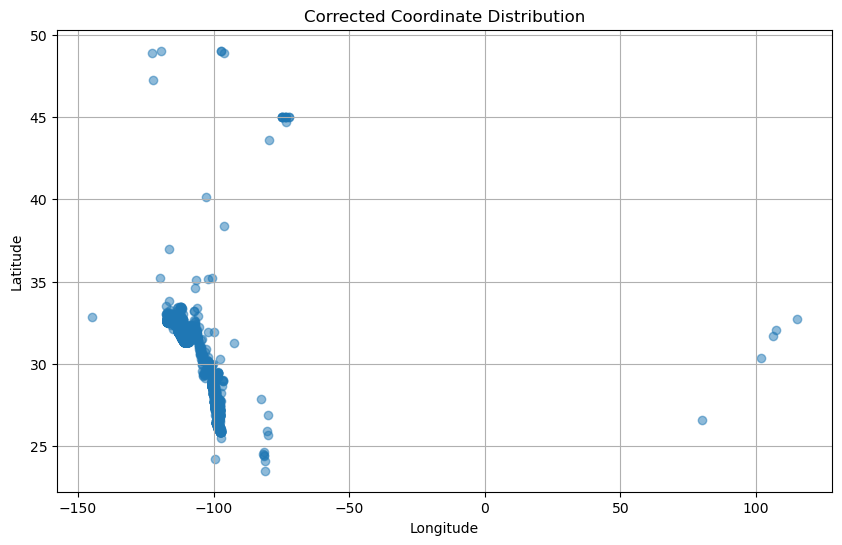

In [15]:
plt.figure(figsize=(10,6))
plt.scatter(migrant_incidents_df['Longitude'], migrant_incidents_df['Latitude'], alpha=0.5)
plt.title('Corrected Coordinate Distribution')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()


In [16]:
import folium
from folium.plugins import MarkerCluster

# Function to choose marker color based on number of deaths
def get_marker_color(deaths):
    try:
        deaths = int(deaths)
        if deaths <= 1:
            return 'green'
        elif deaths <= 5:
            return 'orange'
        else:
            return 'red'
    except:
        return 'gray'

# 1. Create the base map
cleaned_map = folium.Map(
    location=[migrant_incidents_df['Latitude'].mean(), migrant_incidents_df['Longitude'].mean()],
    zoom_start=5,
    tiles='cartodb positron'
)

# 2. Add MarkerCluster
marker_cluster = MarkerCluster(name="Migrant Incidents").add_to(cleaned_map)

# 3. Add Markers
for idx, row in migrant_incidents_df.iterrows():
    popup_html = f"""
    <strong>Date:</strong> {row.get('Incident Date', 'Unknown')}<br>
    <strong>Deaths:</strong> {row.get('Total Number of Dead and Missing', 'Unknown')}
    """

    marker_color = get_marker_color(row.get('Total Number of Dead and Missing', 0))

    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=folium.Popup(popup_html, max_width=300),
        icon=folium.Icon(color=marker_color, icon='info-sign')
    ).add_to(marker_cluster)

# 4. Create a custom legend (HTML + CSS)
legend_html = """
<div style="
position: fixed;
bottom: 50px; left: 50px; width: 200px; height: 140px;
background-color: white;
border:2px solid grey;
z-index:9999;
font-size:14px;
padding: 10px;
">
<b>Legend: Deaths per Incident</b><br>
<i class="fa fa-map-marker fa-2x" style="color:green"></i> 0–1 deaths<br>
<i class="fa fa-map-marker fa-2x" style="color:orange"></i> 2–5 deaths<br>
<i class="fa fa-map-marker fa-2x" style="color:red"></i> >5 deaths<br>
<i class="fa fa-map-marker fa-2x" style="color:gray"></i> Unknown deaths
</div>
"""
# 5. Add the legend to the map
cleaned_map.get_root().html.add_child(folium.Element(legend_html))

# 6. Show final map
cleaned_map

In [17]:
print(migrant_incidents_df.columns.tolist())


['Main ID', 'Incident ID', 'Incident Type', 'Region of Incident', 'Incident Date', 'Incident Year', 'Month', 'Number of Dead', 'Minimum Estimated Number of Missing', 'Total Number of Dead and Missing', 'Number of Survivors', 'Number of Females', 'Number of Males', 'Number of Children', 'Country of Origin', 'Region of Origin', 'Cause of Death', 'Country of Incident', 'Migration Route', 'Location of Incident', 'Coordinates', 'UNSD Geographical Grouping', 'Information Source', 'URL', 'Source Quality', 'Parsed_Date', 'Date', 'Latitude', 'Longitude']


The migrant_incidents_cluster_map.html visualizes the geographic distribution of migrant deaths and disappearances across North America. Each marker represents a fatal or missing migrant incident, clustered dynamically to show regional concentrations. The map highlights major hotspots of migrant vulnerability, particularly along the U.S.-Mexico border, and offers an interactive, human-centered view of migration crises through space and time.

It is an interactive web map created using Folium, a Python library that serves as a wrapper around Leaflet.js, a popular JavaScript library for interactive maps. This particular map visualizes migrant death incidents across North America. Each incident is represented as a marker placed on a basemap, and to handle the large volume of individual incidents without cluttering the map, these markers are grouped into clusters. This clustering automatically adjusts as users zoom in and out of the map, expanding into individual points when zoomed close and collapsing into summarized clusters when zoomed out.

**Technical Features**

HTML+CSS+JS based map.

Built automatically by Folium in Python.

Clustering makes it easier to handle hundreds of markers without slowing down.

Popups contain basic date, region, and deaths data for each point.

The map is centered approximately on latitude 30.69 and longitude -107.25, which places it near the U.S.Mexico border — an area historically associated with significant migrant movements. It uses a light-themed basemap provided by CARTO (CartoDB positron tiles), giving it a clean and professional background suited for data visualization.

**Significance**

Overall, this visualization transforms otherwise abstract or hidden data about migrant fatalities into an immediate, visceral spatial story. It enables policymakers, researchers, advocates, and the public to engage critically with the realities faced by migrants, helping to ground policy discussions and humanitarian debates in concrete geographic realities.



In [33]:
import plotly.io as pio


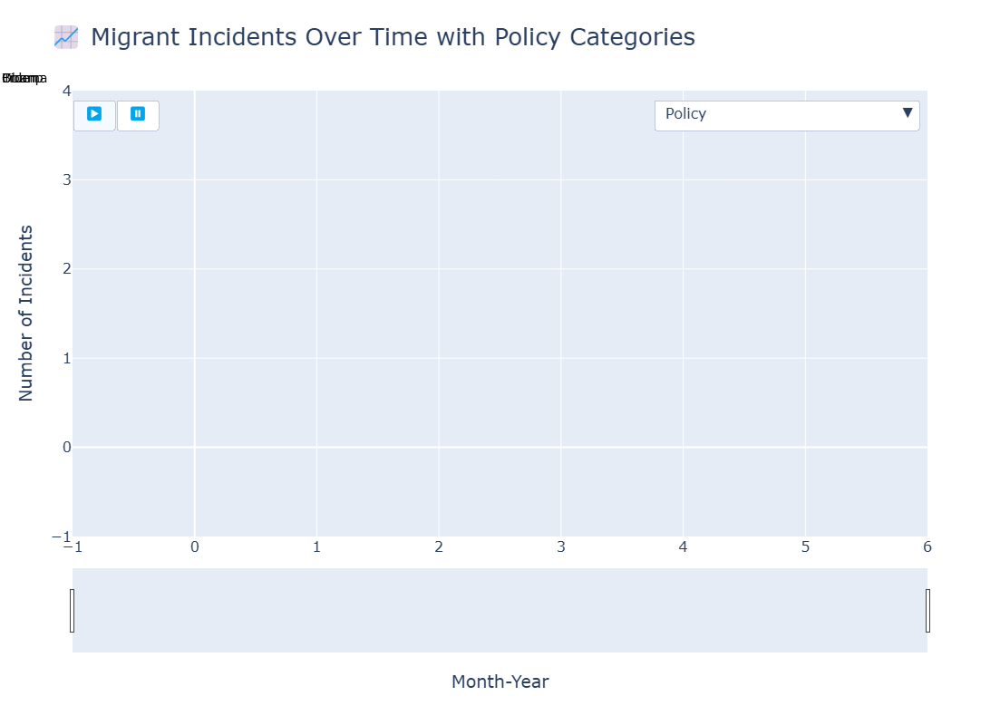

In [27]:
import pandas as pd
import plotly.graph_objects as go

# --- Load and Clean Data ---
def load_and_clean_data():
    migrant_df = pd.read_csv('North_America_Incidents.csv')
    policy_df = pd.read_csv('US CPB POLICIES.csv')

    # Clean column names
    migrant_df.columns = migrant_df.columns.str.strip()
    policy_df.columns = policy_df.columns.str.strip()

    # Rename and filter policies
    policy_df = policy_df.rename(columns={'Policy Year': 'Year', 'Policy Title': 'Policy_Name'})
    policy_df = policy_df.dropna(subset=['Policy_Name'])
    
    # Convert and filter dates
    migrant_df['Incident Date'] = pd.to_datetime(migrant_df['Incident Date'], errors='coerce')
    policy_df['Policy_Date'] = pd.to_datetime(dict(year=policy_df['Year'], month=1, day=1))
    
    # Filter to post-2014 data
    migrant_df = migrant_df[migrant_df['Incident Date'] >= '2014-01-01']
    policy_df = policy_df[policy_df['Policy_Date'] >= '2014-01-01']  # NEW FILTER

    return migrant_df, policy_df



# --- Aggregate Incidents by Month ---
def get_incident_timeseries(migrant_df):
    ts = migrant_df.groupby(migrant_df['Incident Date'].dt.to_period('M')).size().reset_index(name='Incidents')
    ts['Incident Date'] = ts['Incident Date'].dt.to_timestamp()
    return ts

# --- Policy Categories and Colors ---
def categorize_policies(policy_df):
    category_colors = {
        'Executive Orders 13767/13768': '#1b9e77',
        'Title 42/8': '#d95f02',
        'Priority Enforcement Program': '#7570b3',
        'Other': '#e7298a'
    }
    
    policy_df['Category'] = 'Other'
    
    # Executive Orders
    policy_df.loc[policy_df['Policy_Name'].str.contains('13767|13768', regex=True), 'Category'] = 'Executive Orders 13767/13768'
    
    # Title 42/8 combination
    policy_df.loc[policy_df['Policy_Name'].str.contains('Title 42|Title 8', case=False), 'Category'] = 'Title 42/8'
    
    # Priority Enforcement Program
    policy_df.loc[policy_df['Policy_Name'].str.contains('Priority Enforcement Program|PEP', case=False), 'Category'] = 'Priority Enforcement Program'
    
    return policy_df, category_colors
# --- Define Presidential Eras ---
def get_presidential_eras():
    return [
        {"president": "Obama", "start": "2014-01-20", "end": "2017-01-20", "color": "#a6cee3"},
        {"president": "Trump", "start": "2017-01-20", "end": "2021-01-20", "color": "#fdbf6f"},
        {"president": "Biden", "start": "2021-01-20", "end": "2025-01-20", "color": "#b2df8a"},
    ]

# --- Create Animation Frames ---
def build_frames(ts):
    frames = []
    for i in range(len(ts)):
        frames.append(go.Frame(
            data=[go.Scatter(
                x=ts.loc[:i, 'Incident Date'],
                y=ts.loc[:i, 'Incidents'],
                mode='lines+markers',
                line=dict(color='crimson', width=3)
            )],
            name=str(ts.loc[i, 'Incident Date'])[:7]
        ))
    return frames

# --- Build Filter Buttons ---
def build_filter_buttons(policy_df, category_colors, ts, eras):
    buttons = []
    
    # Create permanent presidential elements
    pres_shapes = [
        dict(type="rect",
             x0=era['start'], x1=era['end'],
             y0=0, y1=1, xref="x", yref="paper",
             fillcolor=era["color"], opacity=0.3,
             layer="below", line_width=0)
        for era in eras
    ]
    
    pres_annotations = [
        dict(x=era['start'], y=1.05, xref="x", yref="paper",
             text=era['president'], showarrow=False,
             font=dict(size=14, color="black"), xanchor="left")
        for era in eras
    ]

    # All Policies button
    all_annotations = pres_annotations.copy()
    all_shapes = pres_shapes.copy()
    for idx, row in policy_df.iterrows():
        color = category_colors[row['Category']]
        y_pos = 0.85 if idx % 2 == 0 else 0.15
        all_annotations.append(dict(
            x=row['Policy_Date'], y=y_pos, yref="paper",
            ax=0, ay=40 if y_pos < 0.5 else -40,
            text=row['Policy_Name'], showarrow=True,
            arrowhead=2, font=dict(color=color, size=11),
            bgcolor='white', bordercolor=color, borderwidth=1
        ))
        all_shapes.append(dict(
            type='line',
            x0=row['Policy_Date'], x1=row['Policy_Date'],
            y0=0, y1=ts['Incidents'].max()*1.1,
            line=dict(color=color, dash='dash', width=2)
        ))
    
    buttons.append(dict(
        label="Policy",
        method="relayout",
        args=[{"annotations": all_annotations, "shapes": all_shapes}]
    ))
    
    # Category buttons
    for category, color in category_colors.items():
        if category == 'Other': continue  # Skip "Other" category
        
        cat_annotations = pres_annotations.copy()
        cat_shapes = pres_shapes.copy()
        
        for idx, row in policy_df[policy_df['Category'] == category].iterrows():
            y_pos = 0.85 if idx % 2 == 0 else 0.15
            cat_annotations.append(dict(
                x=row['Policy_Date'], y=y_pos, yref="paper",
                ax=0, ay=40 if y_pos < 0.5 else -40,
                text=row['Policy_Name'], showarrow=True,
                arrowhead=2, font=dict(color=color, size=11),
                bgcolor='white', bordercolor=color, borderwidth=1
            ))
            cat_shapes.append(dict(
                type='line',
                x0=row['Policy_Date'], x1=row['Policy_Date'],
                y0=0, y1=ts['Incidents'].max()*1.1,
                line=dict(color=color, dash='dash', width=2)
            ))
        
        buttons.append(dict(
            label=category,
            method="relayout",
            args=[{"annotations": cat_annotations, "shapes": cat_shapes}]
        ))
    
    return buttons, pres_annotations, pres_shapes

# --- Create and Show Plot ---
def plot_migrant_policy_trends():
    migrant_df, policy_df = load_and_clean_data()
    ts = get_incident_timeseries(migrant_df)
    policy_df, category_colors = categorize_policies(policy_df)
    eras = get_presidential_eras()
    frames = build_frames(ts)
    # buttons = build_filter_buttons(policy_df, category_colors, ts)

    buttons, pres_annotations, pres_shapes = build_filter_buttons(policy_df, category_colors, ts, eras)
    
    # fig = go.Figure()
    
    fig = go.Figure()

    # Add presidential era shading
    for era in eras:
        fig.add_vrect(
    x0=era['start'], x1=era['end'],
    fillcolor=era['color'], 
    opacity=0.3,
    layer="below", 
    line_width=0,
    annotation_text=era['president'],
    annotation_position="top left",
    annotation=dict(
        font_size=16,
        font_color="black",
        y=0.6,  # Changed from default 0.9 to lower position
        yanchor='top'  # Anchors text at the top of the annotation
    )
)

    fig.add_trace(go.Scatter(
        x=[], y=[], mode='lines+markers',
        line=dict(color='crimson', width=3),
        name='Migrant Incidents'
    ))

    fig.frames = frames

    fig.update_layout(
        title='📈 Migrant Incidents Over Time with Policy Categories',
        title_font_size=26,
        xaxis_title='Month-Year',
        yaxis_title='Number of Incidents',
        font=dict(size=16),
        hovermode="x unified",
        shapes=pres_shapes,
        annotations=pres_annotations,
        width=1000, height=800,
        xaxis=dict(
            range=['2014-01-01', ts['Incident Date'].max()],
            tickformat="%b %Y",
            rangeslider=dict(visible=True)
        
        ),
        updatemenus=[
            dict(
                type="buttons", direction="left",
                x=0, xanchor="left", y=1, yanchor="top",
                pad={"r": 10, "t": 10},
                buttons=[
                    dict(label="▶️", method="animate", args=[None, {"frame": {"duration": 300, "redraw": True}, "fromcurrent": True}]),
                    dict(label="⏸️", method="animate", args=[[None], {"frame": {"duration": 0, "redraw": False}, "mode": "immediate"}]),
                ]
            ),
            dict(
                type="dropdown", direction="down",
                x=1, xanchor="right", y=1, yanchor="top",
                pad={"r": 10, "t": 10},
                showactive=True,
                buttons=buttons
            )
        ]
    )
    fig.write_html("migrant_incidents_timeline_1.html")
    fig.show()

# --- Run ---
plot_migrant_policy_trends()



This dashboard provides an interactive visualization of migrant death and disappearance incidents across North America, organized month-by-month over multiple years. It also intersects important US immigration policy especially as it relates to category 'inadmissible' and 'expulsion' through vhanging regimes. The time scope spans from 2014- 2023. Built using Plotly and exported as a standalone HTML file, the dashboard enables dynamic exploration of temporal patterns in migrant vulnerability. Users can animate the timeline, filter incidents by year, and manually navigate across months using embedded dropdowns, sliders, and play/pause controls. By translating raw incident data into an accessible, animated timeline, the dashboard highlights seasonal spikes, long-term trends, and moments of intensified risk. It serves as a portable, fully offline tool for researchers, policymakers, humanitarian advocates, and educators seeking to visualize the spatial and temporal dimensions of migrant crises. The dashboard's self-contained design allows it to be easily shared and embedded in reports, presentations, and public-facing digital archives.

**Technical Features**

Embedded Plotly.js library (~very large script inside!).

Embedded JSON objects for your figures data, layout, and animation frames.

No external dependencies are required: offline and portable.

**What it is visualizing**:

Time series of migrant incidents, organized by month and year.

Animation frames allow viewers to watch changes over time.

Dropdown menu lets users filter by year (or see "All Years").

Play/Pause buttons let users animate the changes across months.

Slider at the bottom allows manual navigation across dates.

The dashboard helps reveal seasonal patterns, spikes, and trends in migrant incidents over multiple years.

In [ ]:
from IPython.display import display, HTML

# Adjusted Styling for HTML headings and links
display(HTML("""
<style>
h1, h2, h3 {
  font-family: 'Segoe UI', 'Arial', sans-serif;
  font-weight: 600;
  color: #2C3E50;
  text-align: center;
  margin-bottom: 10px;
}

p {
  font-family: 'Segoe UI', 'Arial', sans-serif;
  font-size: 16px;
  color: #555;
  text-align: center;
  margin-bottom: 20px;
}

a {
  font-family: 'Segoe UI', 'Arial', sans-serif;
  font-size: 18px;
  color: #1ABC9C;
  text-decoration: none;
  font-weight: 600;
}

a:hover {
  text-decoration: underline;
  color: #16A085;
}

body {
  background-color: #F9F9F9;
}
</style>
"""))


In [ ]:
# Save your Folium map
dynamic_map.save('/content/migrant_incidents_map.html')

print("✅ Folium map saved successfully as migrant_incidents_map.html")
